In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             roc_auc_score, precision_score, recall_score, f1_score)

CSV_PATH = 'creditcard.csv'
if not os.path.exists(CSV_PATH):
    import kagglehub
    CSV_PATH = os.path.join(kagglehub.dataset_download('mlg-ulb/creditcardfraud'), 'creditcard.csv')

df = pd.read_csv(CSV_PATH)
print('Размер данных:', df.shape)
print('Транзакций с мошенничеством:', int(df['Class'].sum()), '(%.3f%%)' % (df['Class'].mean() * 100))

c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Размер данных: (284807, 31)
Транзакций с мошенничеством: 492 (0.173%)


In [ ]:
X = df.drop(columns='Class')
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_test = X_train.copy(), X_test.copy()
scaler = StandardScaler().fit(X_train[['Time', 'Amount']])
X_train[['Time', 'Amount']] = scaler.transform(X_train[['Time', 'Amount']])
X_test[['Time', 'Amount']] = scaler.transform(X_test[['Time', 'Amount']])

fraud_rate = y_train.mean()
print('Train:', X_train.shape, '| мошенничеств:', int(y_train.sum()))
print('Test: ', X_test.shape, '| мошенничеств:', int(y_test.sum()))
print('Доля мошенничества в train: %.5f' % fraud_rate)

Train: (227845, 30) | мошенничеств: 394
Test:  (56962, 30) | мошенничеств: 98
Доля мошенничества в train: 0.00173


In [ ]:
X_train_normal = X_train[y_train == 0]

iforest = IsolationForest(n_estimators=100, contamination=fraud_rate, random_state=42, n_jobs=-1)
iforest.fit(X_train_normal)

if_train_scores = iforest.score_samples(X_train_normal)
if_test_scores = iforest.score_samples(X_test)
print('Isolation Forest обучен на', len(X_train_normal), 'нормальных транзакциях')

Isolation Forest обучен на 227451 нормальных транзакциях


In [4]:
lof = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=fraud_rate, n_jobs=-1)
lof.fit(X_train_normal)

lof_train_scores = lof.negative_outlier_factor_
lof_test_scores = lof.score_samples(X_test)
print('LOF обучен')

c:\Users\Admin\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


LOF обучен


In [5]:
def predict_fraud(train_scores, test_scores, contamination):
    """1 - мошенничество, 0 - нормальная транзакция."""
    threshold = np.percentile(train_scores, 100 * contamination)
    return (test_scores < threshold).astype(int)

models = {
    'Isolation Forest': (if_train_scores, if_test_scores),
    'Local Outlier Factor': (lof_train_scores, lof_test_scores),
}

rows = []
for name, (train_scores, test_scores) in models.items():
    pred = predict_fraud(train_scores, test_scores, fraud_rate)
    rows.append({
        'Модель': name,
        'PR-AUC': average_precision_score(y_test, -test_scores),
        'ROC-AUC': roc_auc_score(y_test, -test_scores),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
    })
results = pd.DataFrame(rows).set_index('Модель')
print(results.round(4).to_string())
print()
print('Доля мошенничества в test (PR-AUC случайного классификатора): %.4f' % y_test.mean())
print('Лучшая модель по PR-AUC:', results['PR-AUC'].idxmax())

                      PR-AUC  ROC-AUC  Precision  Recall      F1
Модель                                                          
Isolation Forest      0.1741   0.9534     0.2426  0.3367  0.2821
Local Outlier Factor  0.0068   0.7120     0.0000  0.0000  0.0000

Доля мошенничества в test (PR-AUC случайного классификатора): 0.0017
Лучшая модель по PR-AUC: Isolation Forest


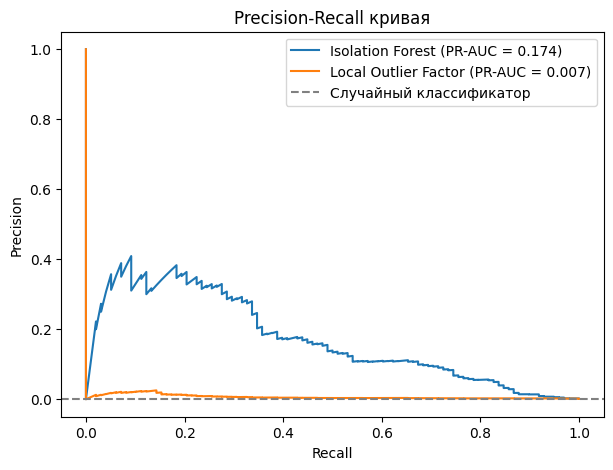

In [6]:
plt.figure(figsize=(7, 5))
for name, (train_scores, test_scores) in models.items():
    precision, recall, _ = precision_recall_curve(y_test, -test_scores)
    plt.plot(recall, precision, label='%s (PR-AUC = %.3f)' % (name, results.loc[name, 'PR-AUC']))
plt.axhline(y_test.mean(), color='gray', linestyle='--', label='Случайный классификатор')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall кривая')
plt.legend()
plt.show()

In [7]:
rows = []
for name, (train_scores, test_scores) in models.items():
    for contamination in [fraud_rate, 0.001]:
        pred = predict_fraud(train_scores, test_scores, contamination)
        rows.append({
            'Модель': name,
            'contamination': round(contamination, 5),
            'Помечено как мошенничество': int(pred.sum()),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred),
        })
print(pd.DataFrame(rows).round(4).to_string(index=False))

              Модель  contamination  Помечено как мошенничество  Precision  Recall     F1
    Isolation Forest         0.0017                         136     0.2426  0.3367 0.2821
    Isolation Forest         0.0010                          99     0.2929  0.2959 0.2944
Local Outlier Factor         0.0017                         102     0.0000  0.0000 0.0000
Local Outlier Factor         0.0010                          67     0.0000  0.0000 0.0000
